# Monte Carlo Simulation of JKJ3B Model for NiX2
### Purposes : 
simulate the JKJ3B model $$ $$ and track how spin-order, polarization evolves with temperature

### Step 1 : Import

In [2]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

print(Path.cwd())

from nix2_mc import LatticeNiX2, SpinModelNiX2, MonteCarloNiX2
from nix2_mc_output import create_run_folder, save_temperature_results

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
d:\GitHub_REPOSITORY\Spin_Models_REPO\NiX2_SPINS


In [3]:
from nix2_model_builders import *

### Step 2 : Lattice

In [4]:
Lmuc = 7
Nmuc = 4
Na = Nmuc * Lmuc
# Nb = 2 * Na
Nb = 2
lattice_geometry = "rectangular"

nix2_lattice = build_nix2_lattice(Na, Nb, geometry=lattice_geometry)

### Step 3 : JKJ3B Model

a model from the PRL 2023

In [5]:
# ================================
# J1prime & Kitaev parameters
# ================================
J1prime = -4.976
Kitaev = 0.858
J1mat = exchange_from_hk(J1prime, Kitaev)
J1iso = np.sum(np.diag(J1mat))/3
Azz = 0.140 # 0.140

B_biquad = -0.719
J2iso = -0.155
J3iso = 2.250 # J3iso should be positive !!!
J2mat = J2iso * np.eye(3)
J3mat = J3iso * np.eye(3)

# ================================
# J1 tensor
# ================================
# # exchange
# J1iso = -7.0  # meV
# Jxx = -1.0
# Jyy = 1.4
# Jzz = -0.3
# Jyz = -1.4
# J1mat = exchange_from_iso_aniso(J1iso, Jxx=Jxx, Jyy=Jyy, Jzz=Jzz, Jxy=0.0, Jxz=0.0, Jyz=Jyz)

# J2iso = 0.0   # meV
# J3iso = +5.8  # meV

# # single-ion anisotropy
# Azz = 0.6 * np.abs(J1iso)

# B_biquad = 0.0

# ================================
# set up model parameters
# ================================
model_params = {
    "J1": J1mat,
    "J2": J2iso,
    "J3": J3iso,
    "Azz": Azz,
    "B_biquad": B_biquad,
    "zeeman": (0.0, 0.0, 0.0)
}

# build model
nix2_model = build_nix2_model(J1mat, J3=J3iso, J2iso=J2iso, 
                              Azz=Azz, B_biquad=B_biquad, B_field=(0.0, 0.0, 0.0), 
                              geometry=lattice_geometry)

In [6]:
print("ratio of J3 to J1iso : ", J3iso / J1iso)
print("ratio of B to J1iso : ", B_biquad / J1iso)

ratio of J3 to J1iso :  -0.4797441364605543
ratio of B to J1iso :  0.1533049040511727


### Step 4 : add M tensor for polarization calculation

In [7]:
# M is in units of 10^-5 e Angstrom; the resulting P is dipole per Ni.
M01 = np.array([[20, 0, 32], [0, 348, -520], [0, 25, 0]], dtype=float)

prepare_M_tensors(nix2_model, lat=nix2_lattice, M01=M01, lat_geom=lattice_geometry)

In [8]:
import secrets

seed = secrets.randbits(128)
current_rng = np.random.default_rng(seed=seed)
nix2_mc = MonteCarloNiX2(lattice=nix2_lattice, spin_model=nix2_model, seed=seed)

Building M tensor arrays for electric polarization.


In [9]:
# Plotting helpers and common appearance.
from plotting_3d_spins import (
    PLOT_CONFIG, plot_spin_config, plot_spin_texture, plot_spin_angles, plot_curves,
)
plt.rcParams.update(PLOT_CONFIG)

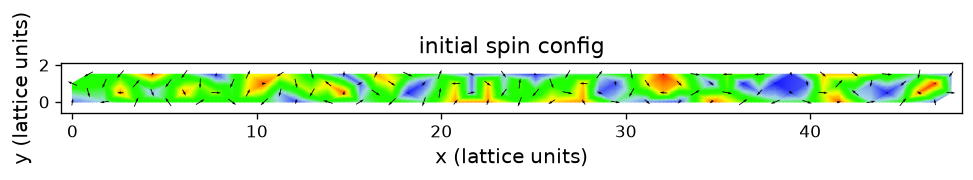

In [10]:
# Current spin configuration: Sz background and in-plane spin arrows.
ax = plot_spin_texture(
    nix2_mc.spin_config, nix2_mc.lat,
    title="initial spin config", figsize=(8,8),colorbar=False
)
plt.show()

### temperatures from HIGH to LOW for annealing
I have checked the validity of this annealing in another notebook

In [11]:
from nix2_mc_protocols import *

In [12]:
# temperatures
TK_init_list = [70, 50, 19]
TK_final_list = [51, 20, 1]
cooling_method_list = ["linear", "linear", "linear"]
cooling_rate_list = [10, 36, 10]

TK_list = set_temperature_schedule(
    TK_init_list, TK_final_list, cooling_method_list, cooling_rate_list,
)

In [13]:
# measurements = make_measurements(
#     nix2_mc,
#     observables=["energy", "magnetization"],
# )

In [14]:
num_eq_sweeps = 10000
converg_per_every = 10
num_meas_sweeps = 15000
meas_per_every = 5

In [15]:
mc_parameters={
    # lattice parameters
    "Nx": Na,
    "Ny": Nb,
    "Ns": nix2_lattice.Ns,
    "geometry": lattice_geometry,
    
    # model parameters
    "model_params": model_params,

    # Monte Carlo parameters
    "seed": seed,
    "num_eq_sweeps": num_eq_sweeps, 
    "converg_per_every": converg_per_every,
    "num_meas_sweeps": num_meas_sweeps, 
    "meas_per_every": meas_per_every,
    "temperatures_info":(TK_init_list, TK_final_list, cooling_method_list, cooling_rate_list),
    "reset_probability": 0.02,
}

current_folder = create_run_folder(root="nix2_simulation_results", parameters=mc_parameters,
                                    prefix="NiX2_JKJ3B_quasi1D_chain_")

### MC Simulation Starts

In [ ]:
from nix2_mc_protocols import run_mc_annealing

results = run_mc_annealing(
    nix2_mc, TK_list, current_folder,
    num_eq_sweeps=num_eq_sweeps,
    num_meas_sweeps=num_meas_sweeps,
    converg_per_every=converg_per_every,
    meas_per_every=meas_per_every,
    observables=["E", "P", "M", "Cv"],
)

T = 70.00 K, energy = -484.094425, electric_polarization = [-4.045352  0.44726  -0.129203], magnetization_norm = 0.128661, magnetization = [-0.013347  0.0019   -0.000643], heat_capacity = 0.950109
T = 67.89 K, energy = -500.297034, electric_polarization = [-1.716316 -1.334925  0.172663], magnetization_norm = 0.12561, magnetization = [ 0.01256   0.002459 -0.005037], heat_capacity = 0.91079
T = 65.78 K, energy = -521.493083, electric_polarization = [ 3.339291 -0.97821   0.216982], magnetization_norm = 0.127491, magnetization = [ 0.005283 -0.010501 -0.013767], heat_capacity = 0.950599
T = 63.67 K, energy = -539.238389, electric_polarization = [-4.074994 -0.82673   0.093667], magnetization_norm = 0.12685, magnetization = [2.491982e-03 9.307388e-03 3.021432e-05], heat_capacity = 0.981786
T = 61.56 K, energy = -554.82123, electric_polarization = [-1.754589  1.758655 -0.253265], magnetization_norm = 0.129497, magnetization = [-0.010576 -0.006009  0.012543], heat_capacity = 1.016599
T = 59.44 

### Step 7 : Plotting final spin configuration

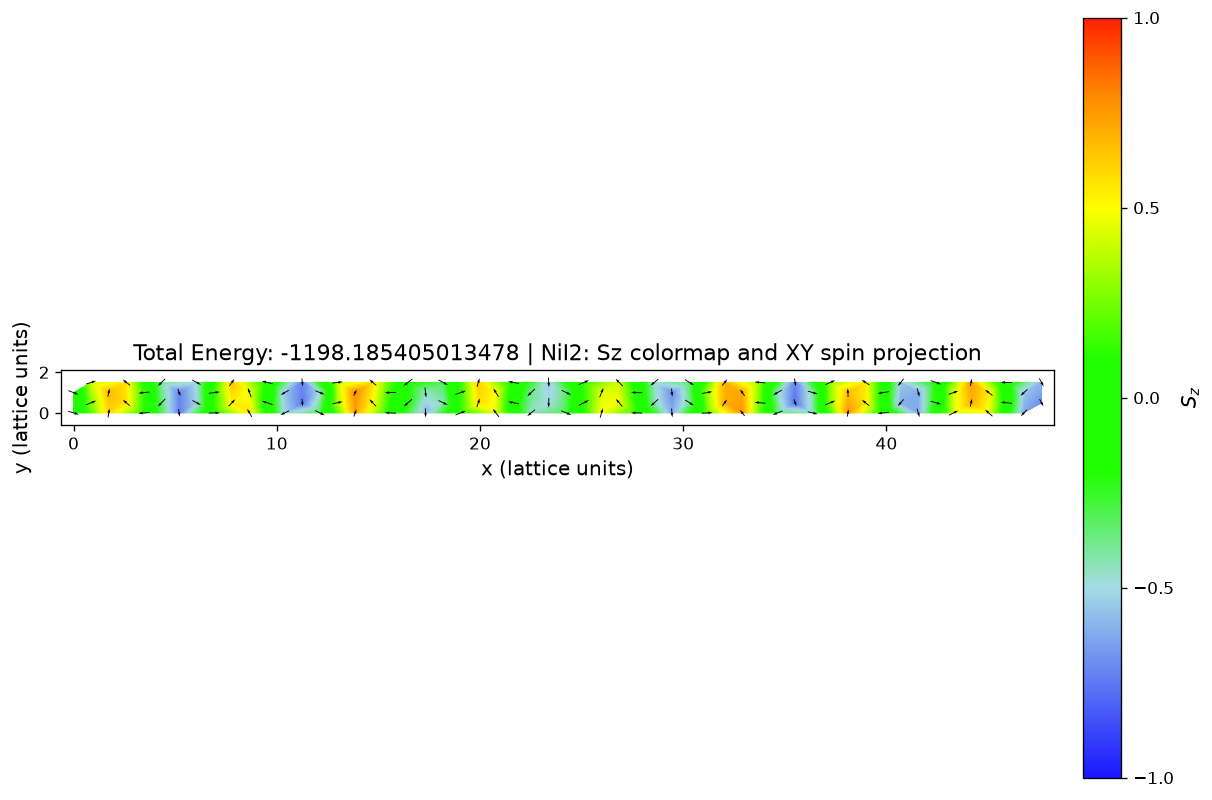

In [17]:
total_energy = nix2_mc.total_energy()

ax = plot_spin_texture(
    spins=nix2_mc.spin_config,
    lattice=nix2_mc.lat,
    title=f"Total Energy: {total_energy} | NiI2: Sz colormap and XY spin projection",
    figsize=(10, 8),
    arrow_scale=1.8,
    arrow_width=0.045,
)
plt.show()

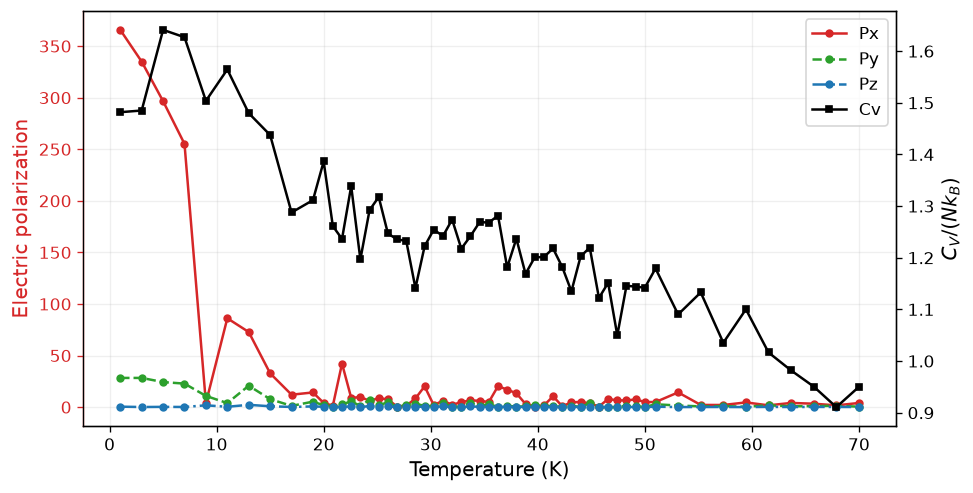

In [18]:
fig, ax1, ax2 = plot_curves(
    results["temperatures_K_list"], np.abs(results["P_data"]).T, results["Cv_data"],
    xlabel="Temperature (K)",
    ylabel1="Electric polarization", ylabel2=r"$C_V/(N k_B)$",
    label1=["Px", "Py", "Pz"], label2="Cv",
    colors=(["tab:red", "tab:green", "tab:blue"], "black"),
    flag_show=True,
)

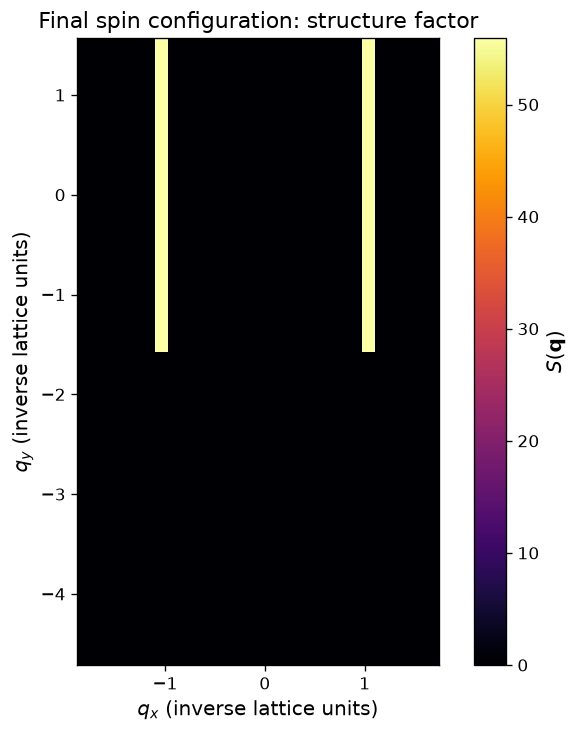

In [ ]:
# Structure factor of the current final spin configuration.
q1, q2, S_q = nix2_mc.spin_structure_factor()
h, k = np.meshgrid(np.fft.fftshift(q1) / nix2_mc.lat.Nx,
                   np.fft.fftshift(q2) / nix2_mc.lat.Ny, indexing="ij")
b1, b2 = 2 * np.pi * np.linalg.inv(nix2_mc.lat.a_vecs).T
qx, qy = h * b1[0] + k * b2[0], h * b1[1] + k * b2[1]

fig, ax = plt.subplots(figsize=(7, 6), constrained_layout=True)
image = ax.pcolormesh(qx, qy, np.fft.fftshift(S_q), shading="auto", cmap="inferno")
fig.colorbar(image, ax=ax, label=r"$S(\mathbf{q})$")
ax.set(xlabel=r"$q_x$ (inverse lattice units)",
       ylabel=r"$q_y$ (inverse lattice units)", aspect="equal",
       title="Final spin configuration: structure factor")
plt.show()

### Step 8 : LLG relaxation to reach the local minimum

In [19]:
from nix2_llg import get_torques, LLG_relaxation, relax_spins

In [23]:
alpha = 100
t_end = 100.0  # ps
energy_before_llg = nix2_mc.total_energy()
# relax spins using LLG
spins_llg = relax_spins(nix2_mc.spin_config, nix2_mc.ham,
                        alpha=alpha, t_end=t_end)

# update the spin configuration
nix2_mc.spin_config = spins_llg.copy()

# compute total energy and maximum torque after relaxation
total_energy = nix2_mc.total_energy()
max_rate = np.max(np.linalg.norm(
    get_torques(alpha, spins_llg, nix2_ham=nix2_mc.ham), axis=-1))
print(f"Energy: {energy_before_llg:.6f} -> {total_energy:.6f} meV")
print(f"Max |dS/dt| = {max_rate:.3e} ps^-1")

Energy: -1209.034155 -> -1209.039000 meV
Max |dS/dt| = 1.290e-04 ps^-1


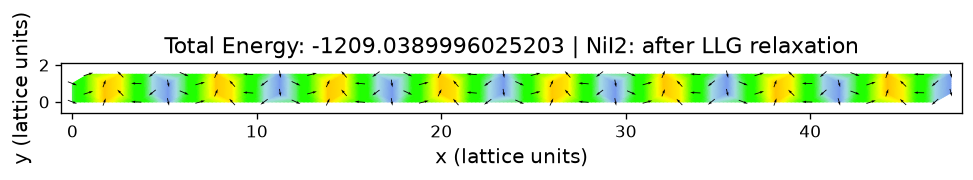

In [24]:
total_energy = nix2_mc.total_energy()

ax = plot_spin_texture(
    spins=spins_llg,
    lattice=nix2_mc.lat,
    title=f"Total Energy: {total_energy} | NiI2: after LLG relaxation",
    figsize=(8, 8),
    arrow_scale=1.8,
    arrow_width=0.045,
    colorbar=False
)
plt.show()

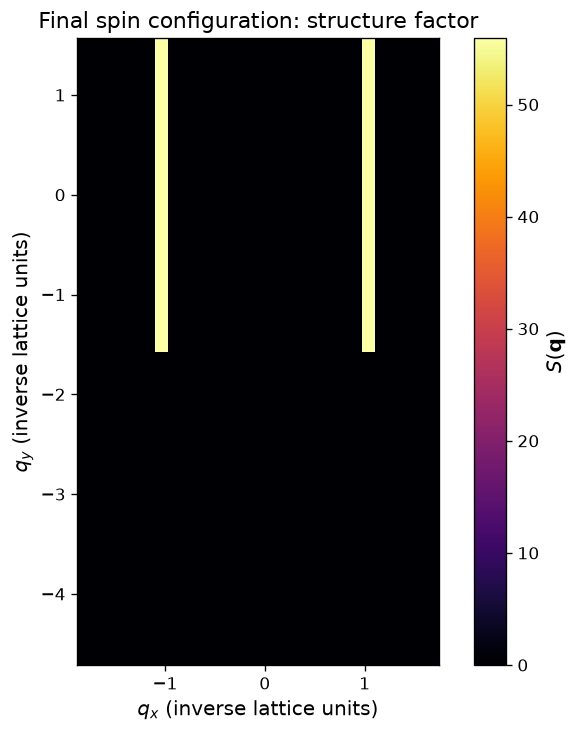

In [ ]:
# Structure factor of the current final spin configuration.
q1, q2, S_q = nix2_mc.spin_structure_factor()
h, k = np.meshgrid(np.fft.fftshift(q1) / nix2_mc.lat.Nx,
                   np.fft.fftshift(q2) / nix2_mc.lat.Ny, indexing="ij")
b1, b2 = 2 * np.pi * np.linalg.inv(nix2_mc.lat.a_vecs).T
qx, qy = h * b1[0] + k * b2[0], h * b1[1] + k * b2[1]

fig, ax = plt.subplots(figsize=(7, 6), constrained_layout=True)
image = ax.pcolormesh(qx, qy, np.fft.fftshift(S_q), shading="auto", cmap="inferno")
fig.colorbar(image, ax=ax, label=r"$S(\mathbf{q})$")
ax.set(xlabel=r"$q_x$ (inverse lattice units)",
       ylabel=r"$q_y$ (inverse lattice units)", aspect="equal",
       title="Final spin configuration: structure factor")
plt.show()